# 01. Exploratory Data Analysis (EDA) — DSC PJATK Catalogue Quality Challenge
Celem notatnika jest:
1. Zrozumienie natury danych i specyfiki syntetycznego katalogu produktów.
2. Analiza rozkładu klas target (wykrywanie wprowadzonych błędów).
3. Weryfikacja braków danych i ich relacji z etykietami.
4. Eksploracja 4 wymiarów potencjalnych zniekształceń: kategorii, liczby sztuk (pack_size), cen (price_pln) oraz wagi (shipping_weight_kg).
5. Analiza zachowania sprzedawców (seller_id) uzasadniająca walidację Group-CV (seller-disjoint).

In [ ]:
import hashlib
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 150

DATA_DIR = Path('../data')
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')

Train shape: (16000, 11)
Test shape:  (10000, 10)


In [13]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  16000 non-null  str    
 1   seller_id           16000 non-null  str    
 2   title               15530 non-null  str    
 3   description         15320 non-null  str    
 4   declared_category   15626 non-null  str    
 5   brand               15053 non-null  str    
 6   condition           16000 non-null  str    
 7   price_pln           15377 non-null  float64
 8   shipping_weight_kg  15038 non-null  float64
 9   pack_size           15515 non-null  float64
 10  target              16000 non-null  int64  
dtypes: float64(3), int64(1), str(7)
memory usage: 1.3 MB


In [14]:
train.head()

,id,seller_id,title,description,declared_category,brand,condition,price_pln,shipping_weight_kg,pack_size,target
0,OFR_191714271,SEL_7523257,recording mic support — pack of one — Mira A513,Pack of one main items. Microphone stand by Mi...,audio,Mira,used,70.43,5.233,1.0,1
1,OFR_517640949,SEL_2053194,in-ear cable headphones — quantity 2 — Noro E315,Included main items: 2. Wired earbuds by Noro....,computers,Noro,used,28.95,0.119,2.0,1
2,OFR_634805877,SEL_8620752,Tenso digital food balance / standard / quanti...,Included main items: 1. Kitchen scale by Tenso...,kitchen,Tenso,new,62.05,0.412,1.0,0
3,OFR_643990737,SEL_8396386,litter scoop — five main items — Velo ...,Cat tray cleaning shovel by Velto. Variant: st...,pets,Velto,used,102.26,0.499,5.0,0
4,OFR_260742748,SEL_5029882,LAPTOP SLEEVE — PACK OF FIVE — ASTER F219,Variant: standard. Also includes 3 pcs of free...,computers,Aster,used,144.84,0.856,5.0,0


In [15]:
for idx, row in train.sample(3, random_state=42).iterrows():
    print(f"ID: {row['id']} | Target: {row['target']} (0=poprawny, 1=błąd)")
    print(f"Tytuł:       {row['title']}")
    print(f"Opis:        {row['description']}")
    print(f"Kategoria:   {row['declared_category']} | Marka: {row['brand']} | Stan: {row['condition']}")
    print(f"Cena:        {row['price_pln']} PLN | Waga: {row['shipping_weight_kg']} kg | Sztuk: {row['pack_size']}")
    print("-" * 80)

ID: OFR_425850375 | Target: 0 (0=poprawny, 1=błąd)
Tytuł:       audio interface — 1-pack — Velto C403
Opis:        Usb recording interface by Velto. Variant: standard. Sold as a 1-pack. Designed for everyday sound use. Packed for delivery.
Kategoria:   music | Marka: Velto | Stan: used
Cena:        213.9 PLN | Waga: 0.637 kg | Sztuk: 1.0
--------------------------------------------------------------------------------
ID: OFR_999534147 | Target: 1 (0=poprawny, 1=błąd)
Tytuł:       Aster picture dictionary / large / 2 pcs
Opis:        Also includes 2 pcs of free accessory pieces; these do not count as main items. Illustrated vocabulary book by Aster. Variant: large. Package contains 2 pcs. Check the edition before ordering. Dispatch from local stock.
Kategoria:   books | Marka: Aster | Stan: new
Cena:        200.7 PLN | Waga: 2.182 kg | Sztuk: 1.0
--------------------------------------------------------------------------------
ID: OFR_112627921 | Target: 0 (0=poprawny, 1=błąd)
Tytuł:    

In [16]:
train.describe().round(2)

,price_pln,shipping_weight_kg,pack_size,target
count,15377.00,15038.00,15515.00,16000.00
mean,145.47,0.98,1.52,0.17
std,212.01,1.65,1.00,0.38
min,0.97,0.02,1.00,0.00
25%,39.67,0.23,1.00,0.00
50%,77.51,0.46,1.00,0.00
75%,166.13,0.99,2.00,0.00
max,3464.27,32.83,5.00,1.00


## 1. Rozkład zmiennej celu (`target`)
Weryfikacja proporcji ofert poprawnych (target=0) do ofert z wprowadzonym błędem syntetycznym (target=1).

target=0 (Brak błędu): 13279 (82.99%)
target=1 (Błąd wprowadzony): 2721 (17.01%)


C:\Users\jan31\AppData\Local\Temp\ipykernel_12580\3288202165.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


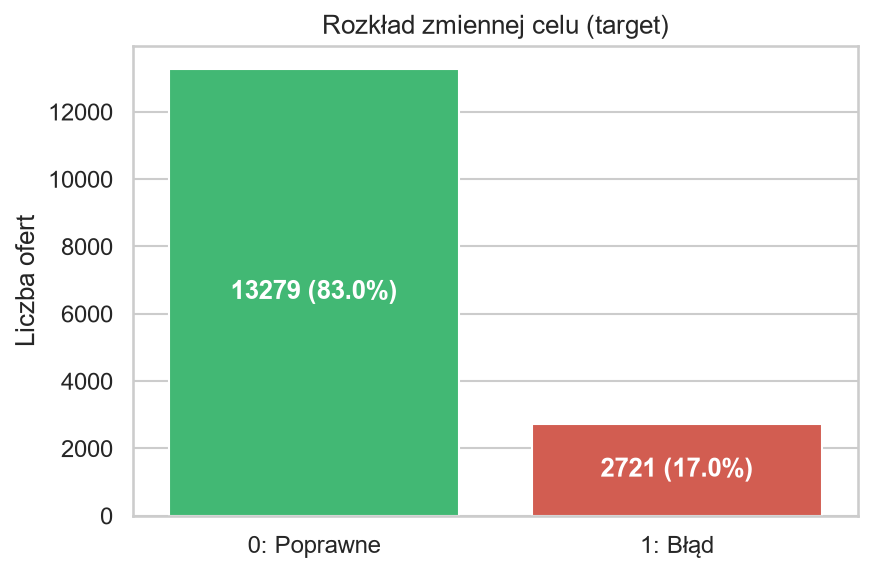

In [ ]:
target_counts = train['target'].value_counts()
target_props = train['target'].value_counts(normalize=True) * 100

print(
    f'target=0 (Brak błędu): {target_counts[0]} ({target_props[0]:.2f}%)'
)  
print(
    f'target=1 (Błąd wprowadzony): {target_counts[1]} ({target_props[1]:.2f}%)'
)  

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(
    x=['0: Poprawne', '1: Błąd'],
    y=target_counts.values,
    palette=['#2ecc71', '#e74c3c'],
    ax=ax,
)
ax.set_title('Rozkład zmiennej celu (target)')
ax.set_ylabel('Liczba ofert')
for p in ax.patches:
  ax.annotate(
      f'{int(p.get_height())} ({p.get_height()/len(train)*100:.1f}%)',
      (p.get_x() + p.get_width() / 2.0, p.get_height() / 2),
      ha='center',
      va='center',
      color='white',
      fontweight='bold',
  )
plt.tight_layout()
plt.show()

## 2. Analiza braków danych (Missing Data Analysis)
Sprawdzamy, czy obecność braków danych (NaN) jest skorelowana z wprowadzonym błędem (target=1), 
czy też braki występują naturalnie i niezależnie w procesie zbierania ofert.

In [ ]:
missing_train = (
    pd.DataFrame({
        'missing_count': train.isna().sum(),
        'missing_pct': (train.isna().mean() * 100).round(2),
    })
    .query('missing_count > 0')
    .sort_values(by='missing_count', ascending=False)
)

print('Braki danych w train.csv:')
print(missing_train)

#odsetek błędów, gdy wartość występuje vs gdy jest pusta
comparison = []
for col in missing_train.index:
  rate_missing = train[train[col].isna()]['target'].mean() * 100
  rate_present = train[train[col].notna()]['target'].mean() * 100
  comparison.append({
      'Kolumna': col,
      'Błąd gdy NaN (%)': round(rate_missing, 2),
      'Błąd gdy Obecna (%)': round(rate_present, 2),
  })

comp_df = pd.DataFrame(comparison)
print('\nPorównanie odsetka błędów w zależności od obecności wartości:')
print(comp_df.to_string(index=False))

Braki danych w train.csv:
                    missing_count  missing_pct
shipping_weight_kg            962         6.01
brand                         947         5.92
description                   680         4.25
price_pln                     623         3.89
pack_size                     485         3.03
title                         470         2.94
declared_category             374         2.34

Porównanie odsetka błędów w zależności od obecności wartości:
           Kolumna  Błąd gdy NaN (%)  Błąd gdy Obecna (%)
shipping_weight_kg             17.46                16.98
             brand             15.52                17.10
       description             15.00                17.10
         price_pln             18.78                16.93
         pack_size             18.14                16.97
             title             14.89                17.07
 declared_category             18.18                16.98


## 3. Analiza sprzedawców (Sellers) i uzasadnienie podziału Seller-Disjoint
Weryfikacja liczby unikalnych sprzedawców, rozłączności między train i test oraz rozkładu ofert na sprzedawcę.

Liczba unikalnych sprzedawców w train: 800
Liczba unikalnych sprzedawców w test:  500
Część wspólna (wyciek): 0 (musi być 0)
Średnia liczba ofert na sprzedawcę: 20.0 (min: 20, max: 20)


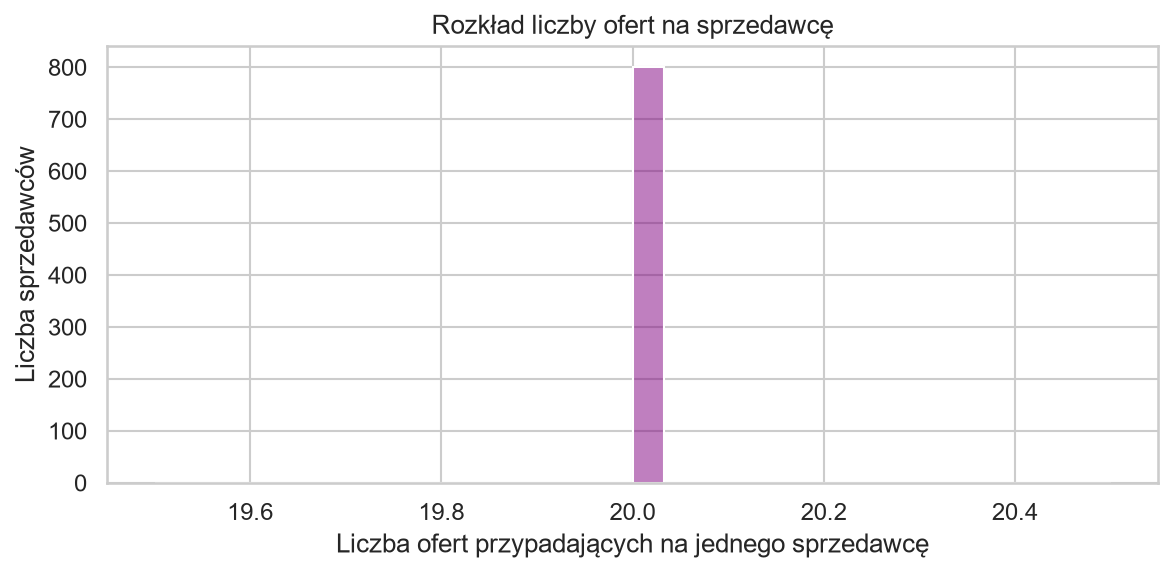

In [ ]:
train_sellers = set(train['seller_id'])
test_sellers = set(test['seller_id'])
overlap = train_sellers.intersection(test_sellers)

print(f'Liczba unikalnych sprzedawców w train: {len(train_sellers)}')
print(f'Liczba unikalnych sprzedawców w test:  {len(test_sellers)}')
print(f'Część wspólna (wyciek): {len(overlap)})  #[cite: 1]

seller_activity = train['seller_id'].value_counts()
print(
    f'Średnia liczba ofert na sprzedawcę: {seller_activity.mean():.1f} (min:'
    f' {seller_activity.min()}, max: {seller_activity.max()})'
)

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(seller_activity, bins=30, kde=True, color='purple', ax=ax)
ax.set_title('Rozkład liczby ofert na sprzedawcę')
ax.set_xlabel('Liczba ofert przypadających na jednego sprzedawcę')
ax.set_ylabel('Liczba sprzedawców')
plt.tight_layout()
plt.show()

## 4. Analiza kategorii i potencjalnych błędów klasyfikacji
Kategorie mają różną liczność (np. music jest kategorią rzadką).

                   total  error_rate
declared_category                   
computers           2759       15.98
audio               2535       14.99
kitchen             2253       17.27
sport               1837       13.99
books               1691       13.54
beauty              1622       15.91
garden              1331       21.11
pets                 863       17.27
music                735       36.60


C:\Users\jan31\AppData\Local\Temp\ipykernel_12580\1097660546.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


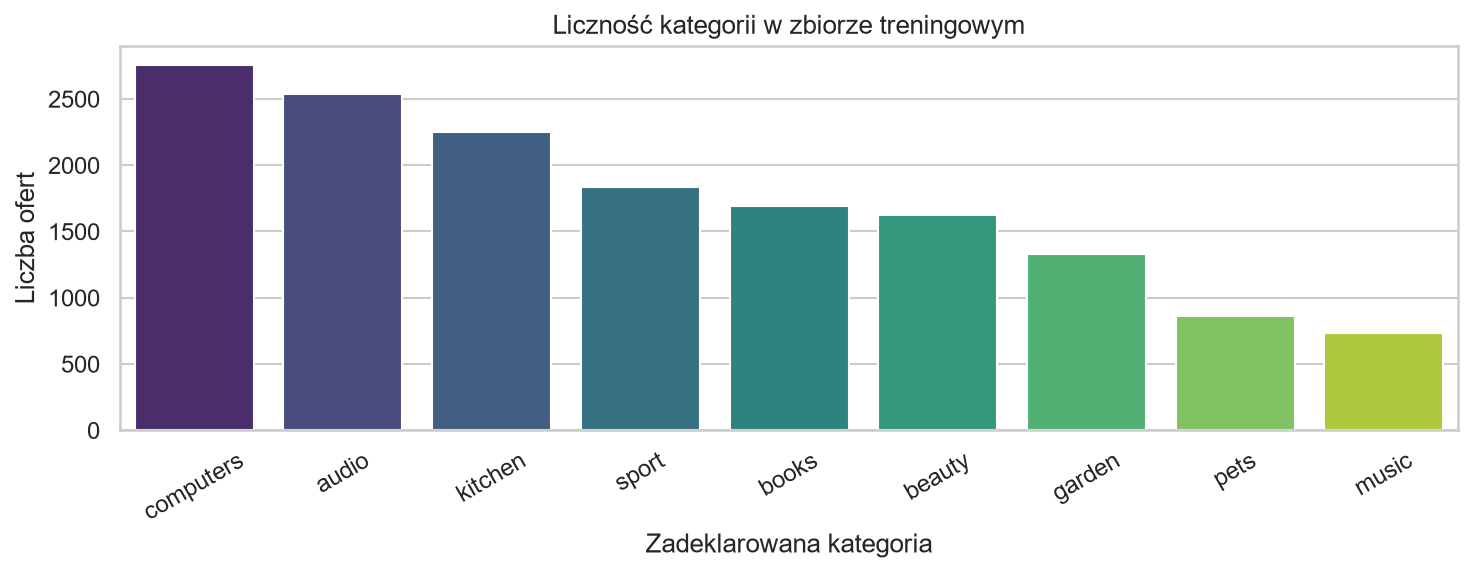

In [7]:
cat_summary = (
    train.groupby('declared_category')
    .agg(
        total=('id', 'count'),
        error_rate=('target', 'mean'),
    )
    .sort_values(by='total', ascending=False)
)
cat_summary['error_rate'] = (cat_summary['error_rate'] * 100).round(2)
print(cat_summary)

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(
    x=cat_summary.index,
    y=cat_summary['total'],
    palette='viridis',
    ax=ax,
)
ax.set_title('Liczność kategorii w zbiorze treningowym')
ax.set_xlabel('Zadeklarowana kategoria')
ax.set_ylabel('Liczba ofert')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 5. Analiza wielkości paczki (pack_size)
Zgodnie z opisem konkursu, deklarowany pack_size to 1, 2, 3 lub 5, a darmowe akcesoria (free accessories) nie powinny go zmieniać.

In [8]:
print('Rozkład pack_size:')
print(train['pack_size'].value_counts(dropna=False).sort_index())

# Sprawdzenie obecności frazy 'free accessory' w tekście
has_accessory = (
    train['description']
    .fillna('')
    .str.contains('free accessor|free piece', case=False)
)
print(
    f'\nLiczba ofert wspominających o gratisach/akcesoriach:'
    f' {has_accessory.sum()}'
)
print(
    'Rozkład pack_size dla ofert z darmowymi akcesoriami:\n',
    train[has_accessory]['pack_size'].value_counts(),
)

Rozkład pack_size:
pack_size
1.0    10986
2.0     2499
3.0     1283
5.0      747
NaN      485
Name: count, dtype: int64

Liczba ofert wspominających o gratisach/akcesoriach: 3865
Rozkład pack_size dla ofert z darmowymi akcesoriami:
 pack_size
1.0    2676
2.0     570
3.0     310
5.0     183
Name: count, dtype: int64


## 6. Analiza cen i wag — Identyfikacja asymetrii i anomalii
Sprawdzamy rozkłady, konieczność transformacji logarytmicznej oraz istnienie skrajnych wartości odstających.

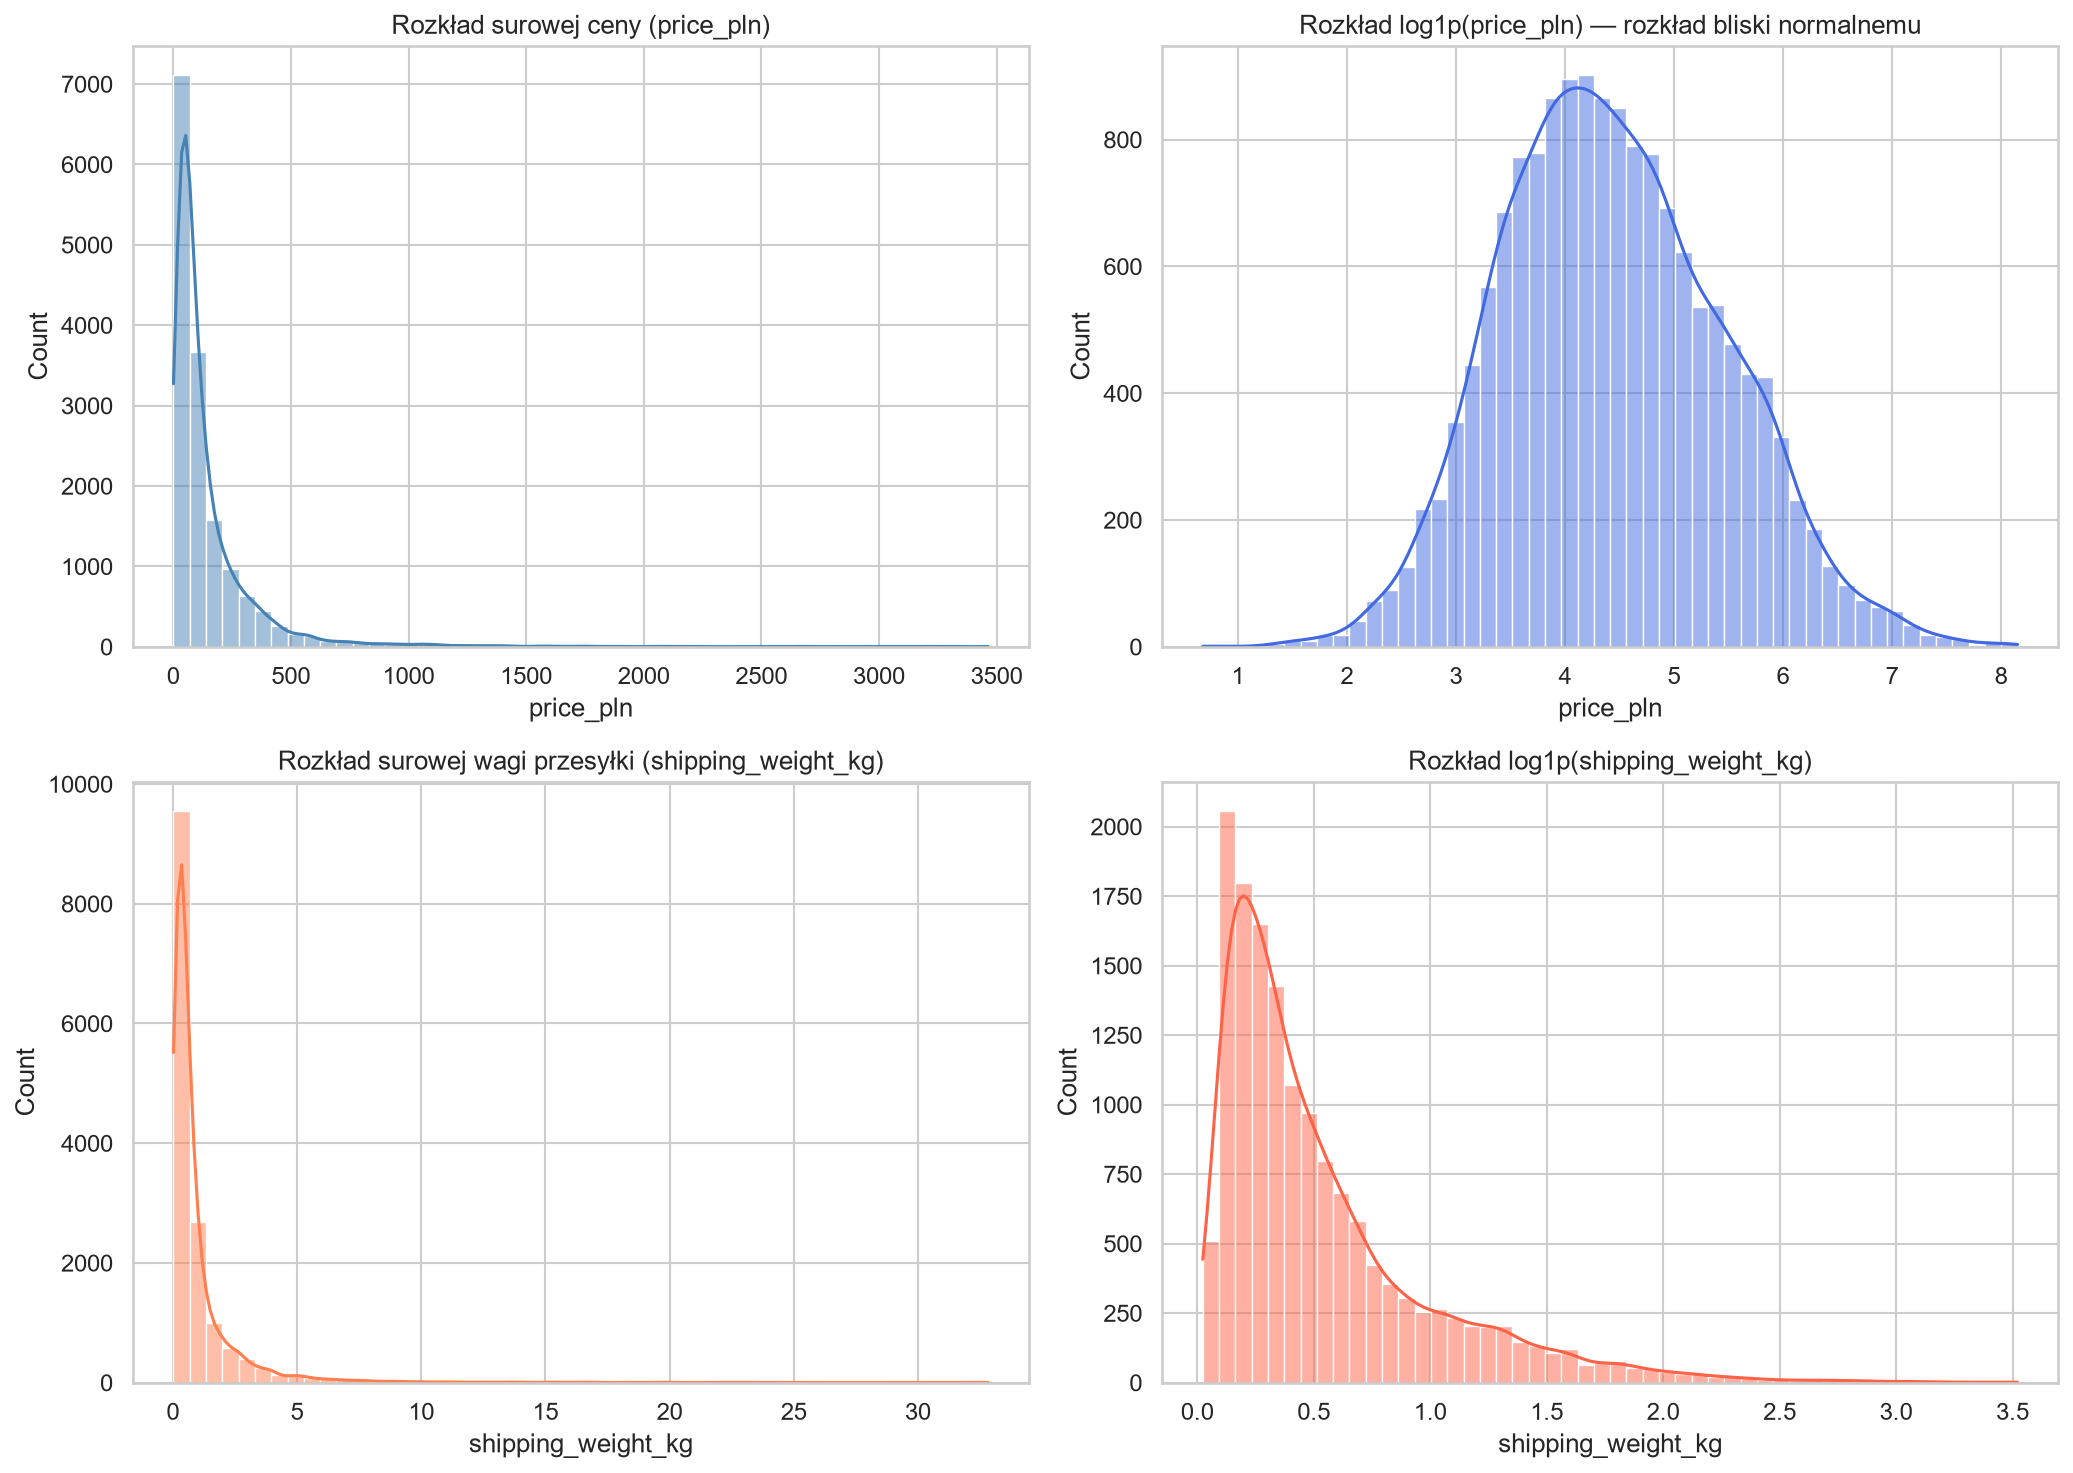

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Surowe ceny
sns.histplot(
    train['price_pln'].dropna(),
    bins=50,
    ax=axes[0, 0],
    color='steelblue',
    kde=True,
)
axes[0, 0].set_title('Rozkład surowej ceny (price_pln)')

# Ceny po logarytmie
sns.histplot(
    np.log1p(train['price_pln'].dropna()),
    bins=50,
    ax=axes[0, 1],
    color='royalblue',
    kde=True,
)
axes[0, 1].set_title('Rozkład log1p(price_pln) - po logarytmie')

# Surowe wagi
sns.histplot(
    train['shipping_weight_kg'].dropna(),
    bins=50,
    ax=axes[1, 0],
    color='coral',
    kde=True,
)
axes[1, 0].set_title('Rozkład surowej wagi przesyłki (shipping_weight_kg)')

# Wagi po logarytmie
sns.histplot(
    np.log1p(train['shipping_weight_kg'].dropna()),
    bins=50,
    ax=axes[1, 1],
    color='tomato',
    kde=True,
)
axes[1, 1].set_title('Rozkład log1p(shipping_weight_kg) - po logarytmie')

plt.tight_layout()
plt.savefig('eda_distributions.png', dpi=300)
plt.show()

## 7. Ceny i Wagi a Kategorie — Uzasadnienie wskaźnika Z-Score
Ceny różnią się diametralnie w zależności od kategorii (np. beauty vs computers), co uzasadnia relatywne liczenie anomalii.

C:\Users\jan31\AppData\Local\Temp\ipykernel_12580\3393702180.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\jan31\AppData\Local\Temp\ipykernel_12580\3393702180.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


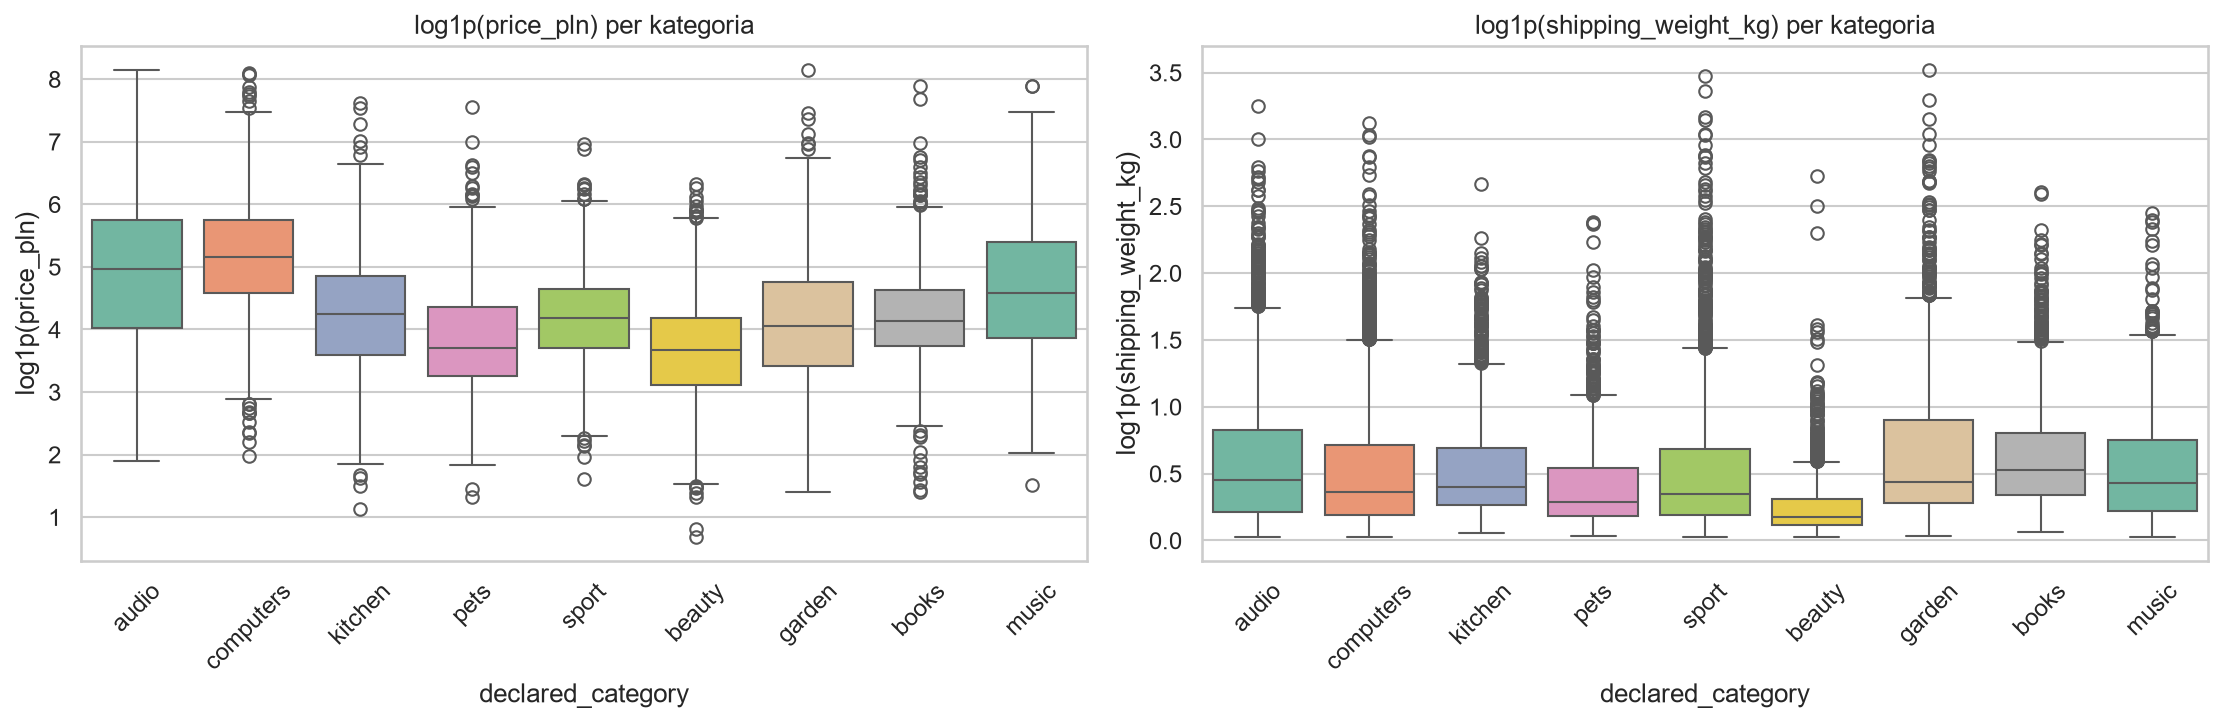

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    data=train,
    x='declared_category',
    y=np.log1p(train['price_pln']),
    ax=axes[0],
    palette='Set2',
)
axes[0].set_title('log1p(price_pln) per kategoria')
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(
    data=train,
    x='declared_category',
    y=np.log1p(train['shipping_weight_kg']),
    ax=axes[1],
    palette='Set2',
)
axes[0].set_ylabel('log1p(price_pln)')
axes[1].set_ylabel('log1p(shipping_weight_kg)')
axes[1].set_title('log1p(shipping_weight_kg) per kategoria')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('eda_category_boxplots.png', dpi=300)
plt.show()

### 7. Analiza długości tekstu (title_len, desc_len) vs target
Sprawdzamy, czy oferty z syntetycznym błędem (`target=1`) charakteryzują się inną długością tytułu lub opisu.

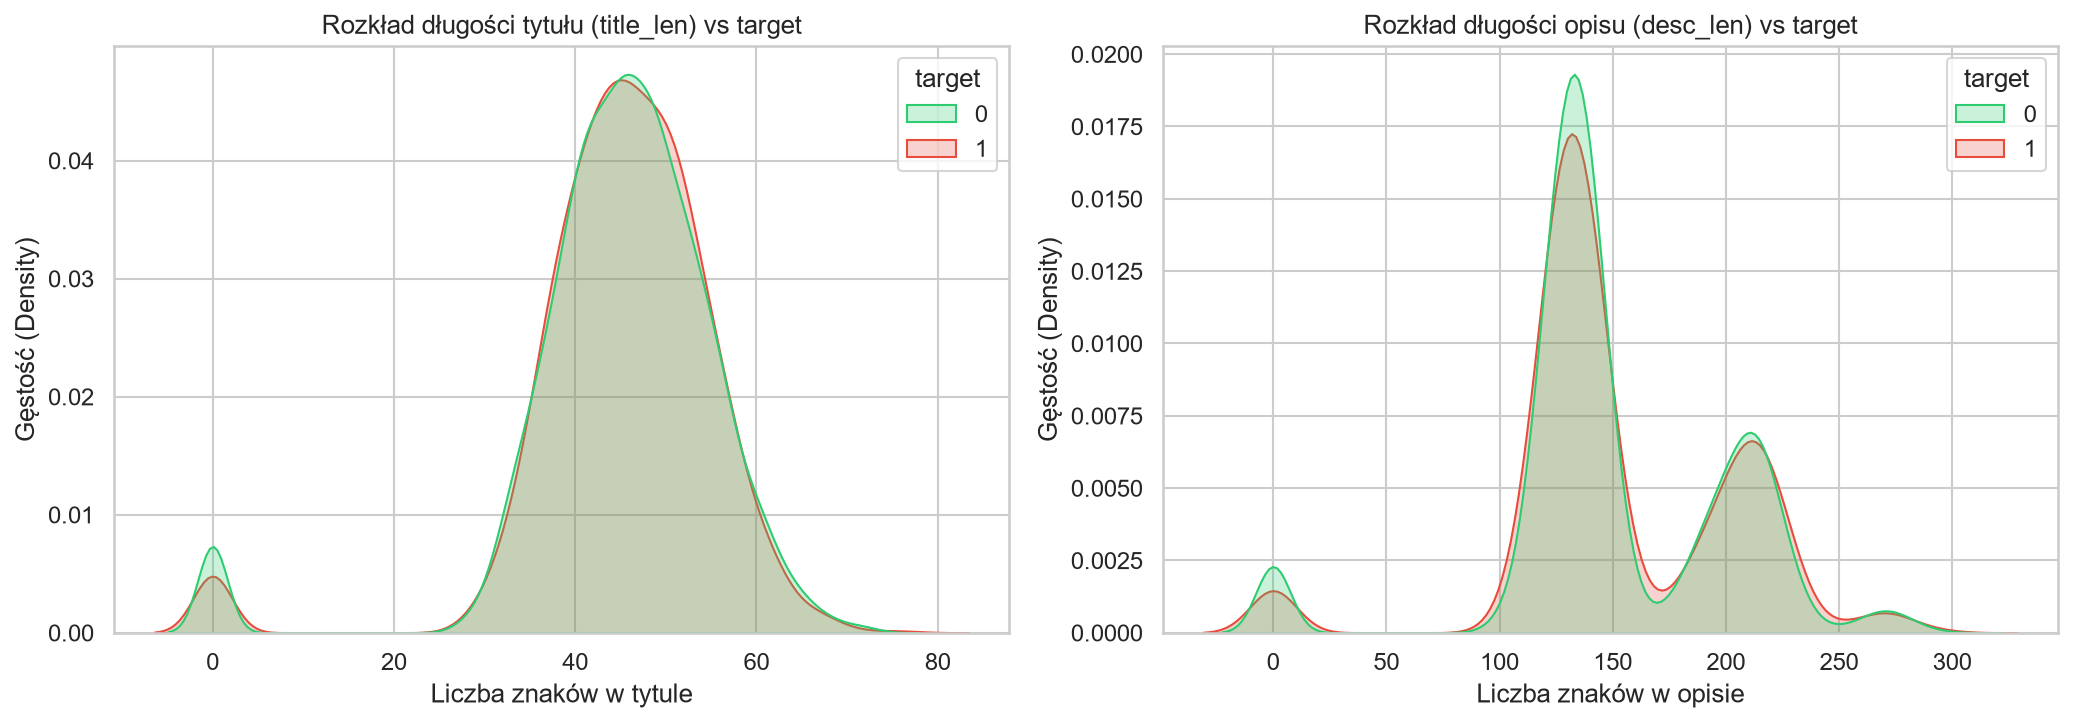

Statystyki opisowe długości tekstu:


,title_len,desc_len
target,,
0,45.05,151.15
1,45.23,152.66


In [19]:
# Obliczenie długości znakowych tytułu i opisu
train['title_len'] = train['title'].fillna('').astype(str).str.len()
train['desc_len'] = train['description'].fillna('').astype(str).str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Wykres gęstości dla długości tytułu
sns.kdeplot(
    data=train,
    x='title_len',
    hue='target',
    common_norm=False,
    fill=True,
    palette=['#2ecc71', '#e74c3c'],
    ax=axes[0],
)
axes[0].set_title('Rozkład długości tytułu (title_len) vs target')
axes[0].set_xlabel('Liczba znaków w tytule')
axes[0].set_ylabel('Gęstość (Density)')

# Wykres gęstości dla długości opisu
sns.kdeplot(
    data=train,
    x='desc_len',
    hue='target',
    common_norm=False,
    fill=True,
    palette=['#2ecc71', '#e74c3c'],
    ax=axes[1],
)
axes[1].set_title('Rozkład długości opisu (desc_len) vs target')
axes[1].set_xlabel('Liczba znaków w opisie')
axes[1].set_ylabel('Gęstość (Density)')

plt.tight_layout()
plt.savefig('eda_text_length.png', dpi=300)
plt.show()

print('Statystyki opisowe długości tekstu:')
display(train.groupby('target')[['title_len', 'desc_len']].mean().round(2))

### 8. Macierz korelacji cech numerycznych z targetem
Syntetyczne podsumowanie zależności liniowych między surowymi atrybutami numerycznymi a występowaniem błędu w ofercie.

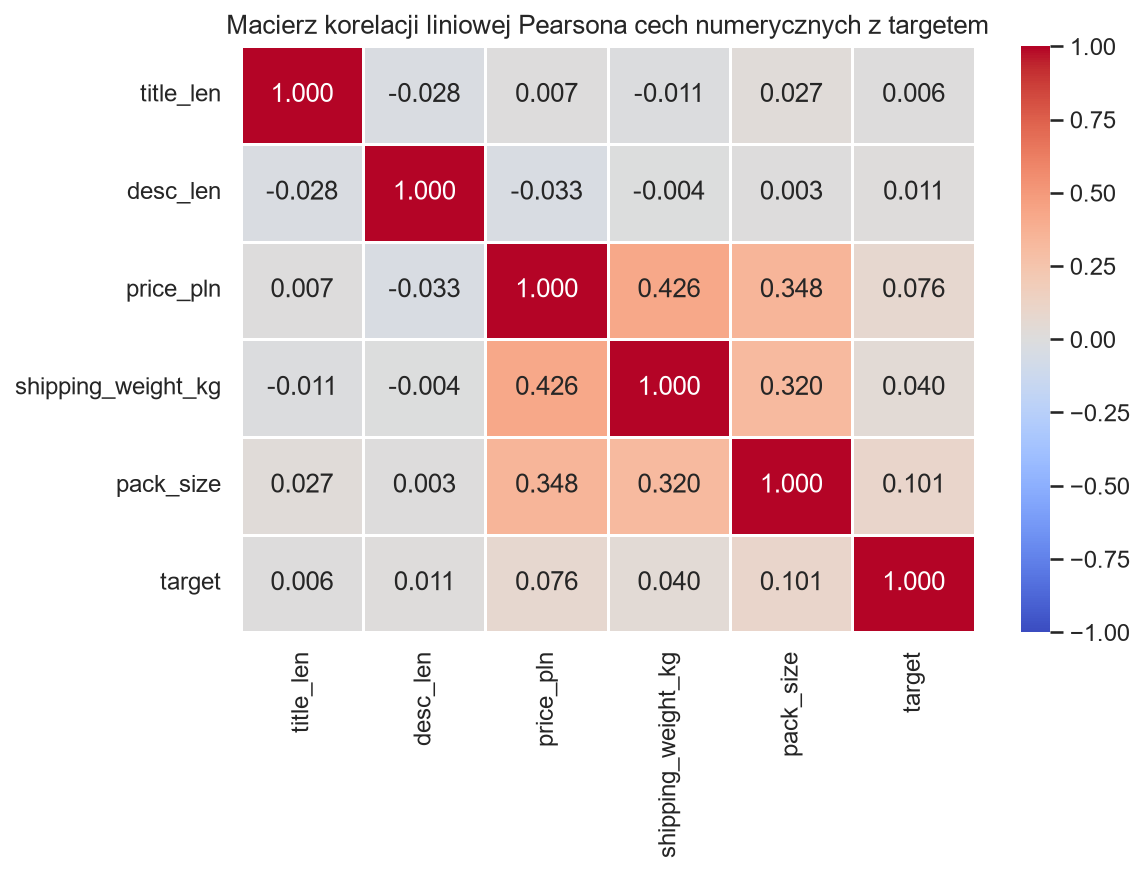

Korelacja cech z targetem (wartości bezwzględne):
pack_size             0.1014
price_pln             0.0760
shipping_weight_kg    0.0399
desc_len              0.0112
title_len             0.0061
Name: target, dtype: float64


In [20]:
num_cols = ['title_len', 'desc_len', 'price_pln', 'shipping_weight_kg', 'pack_size', 'target']

corr_pearson = train[num_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr_pearson,
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=ax
)
ax.set_title('Macierz korelacji liniowej Pearsona cech numerycznych z targetem')
plt.tight_layout()
plt.savefig('eda_correlation_matrix.png', dpi=300)
plt.show()

print('Korelacja cech z targetem (wartości bezwzględne):')
print(corr_pearson['target'].drop('target').sort_values(ascending=False).round(4))

## 8. Kluczowe Wnioski z EDA (Key Takeaways)

1. **Niezbalansowanie klas i dobór metryk:** Klasa pozytywna (`target=1`) stanowi ok. 17,01% zbioru. Metryka Accuracy jest nieprzydatna; sukces modelu należy mierzyć za pomocą PR-AUC oraz ROC-AUC.
2. **Konieczność walidacji Seller-Disjoint:** Zbiory train i test nie dzielą żadnego sprzedawcy (overlap = 0). Ponadto każdy z 800 sprzedawców ma dokładnie 20 ofert. Zbiór walidacyjny musi grupować oferty według `seller_id` (GroupKFold), co gwarantuje brak wycieku danych i idealnie równe foldy.
3. **Brak trywialnych reguł w brakach danych:** Braki danych występują naturalnie w obu klasach (najwięcej w wadze 6,01% i marce 5,92%). Jednak brak ceny lub kategorii podnosi odsetek błędów do ~18,8%, co uzasadnia utworzenie binarnych flag obecności braków.
4. **Logarytmizacja i Z-score per kategoria:** Ceny i wagi wykazują skrajną asymetrię prawostronną. Transformacja `log1p` stabilizuje rozkłady, a anomalie cenowo-wagowe muszą być liczone jako Z-score relatywnie do kategorii oraz po przeliczeniu na pojedynczą sztukę (`unit_price`, `unit_weight`).
5. **Kontekstowy charakter błędów (brak korelacji liniowej):** Surowe cechy numeryczne wykazują niemal zerową korelację liniową z targetem ($r \le 0,101$). Wykrycie błędu wymaga zaawansowanej inżynierii cech mierzącej rozbieżności, a nie surowych wartości.
6. **Silna asymetria błędów per kategoria:** Odsetek błędów waha się od 13,5% w książkach do aż 36,6% w muzyce, co wskazuje na konieczność modelowania prawdopodobieństw kategorii i wykrywania niedopasowań (`category_mismatch`).
7. **Rozbieżności tekst vs tabela (`pack_size`):** Aż 3865 ofert wspomina o darmowych akcesoriach ("free accessories"), które nie powinny wliczać się do głównego wolumenu paczki. Proste parsowanie tekstu zawodzi — konieczna jest dedykowana ekstrakcja intencji rozmiaru paczki.
8. **Struktura tekstu:** Długości znakowe tytułu i opisu nie różnicują klas (krzywe KDE pokrywają się), a wielomodalny rozkład długości opisów świadczy o generowaniu ofert z predefiniowanych szablonów.